# Ingesta y detección de fraude — Etapas 0, 1 y 6

**Autor:** Axel · **Rol:** Ingesta y fraude · Proyecto *pipeline-streams-eda* (EDA, UTEC 2026-2)

Este cuaderno demuestra, de forma interactiva, el aporte del integrante encargado
de la **entrada del pipeline** (etapas 0 y 1) y de la **detección de fraude**
(etapa 6). Reusa el código del repositorio (`src/`) y los datos sintéticos con
semilla (`experimentos/datos_sinteticos.py`).

El hilo conductor es el de estructuras de datos: en cada etapa se elige la
estructura según la pregunta que se hace y se compara contra la alternativa de la
librería estándar.

In [1]:
import sys, os

# Permite ejecutar el cuaderno desde la carpeta notebooks/ o desde la raíz.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if RAIZ not in sys.path:
    sys.path.insert(0, RAIZ)

import matplotlib.pyplot as plt

from experimentos.datos_sinteticos import iterar_eventos, generar_eventos_fraude
from src.etapa0_ingesta import Etapa0Ingesta
from src.etapa1_preprocesamiento import Etapa1Preprocesamiento
from src.etapa6_probabilistico import FiltroBloom, CountMinSketch, Etapa6Fraude

print("Entorno listo. Raíz del proyecto:", RAIZ)

Entorno listo. Raíz del proyecto: C:\Users\User\Axel\Maestria_Ciencia_Datos\CICLO 2\Estrucutura de datos\pipeline-streams-eda


## Etapa 0 — Ingesta y buffer

Recibe el stream y lo entrega por lotes en orden de llegada, como una **cola FIFO**
sobre lista enlazada (encolar/desencolar en **O(1)**). Si el buffer se llena,
aplica contrapresión y no pierde eventos.

In [2]:
e0 = Etapa0Ingesta(capacidad=5_000, tam_lote=1_000)

lotes = list(e0.procesar_stream(iterar_eventos(20_000, semilla=42)))
print(f"Lotes entregados: {len(lotes)}  (tamaños: {lotes[0].__len__()} ... {len(lotes[-1])})")
print("Métricas etapa 0:", e0.metricas())

Lotes entregados: 20  (tamaños: 1000 ... 1000)
Métricas etapa 0: {'recibidos': 20000, 'entregados': 20000, 'lotes': 20, 'en_buffer': 0, 'contrapresion': 0}


## Etapa 1 — Preprocesamiento por lote

Valida y normaliza cada evento, lo **ordena por tiempo** con *merge sort* estable
(**O(n log n)**) y **deduplica** comparando vecinos (**O(n)**). Mide su calidad
contra la etiqueta `es_duplicado` del generador.

In [3]:
e0 = Etapa0Ingesta(capacidad=5_000, tam_lote=1_000)
e1 = Etapa1Preprocesamiento()

total_entregados = 0
for lote in e0.procesar_stream(iterar_eventos(20_000, semilla=42, prop_duplicados=0.05, prop_invalidos=0.01)):
    total_entregados += len(e1.procesar(lote).eventos)

m1 = e1.metricas()
print(f"Recibidos: {m1['recibidos']}  |  Entregados limpios: {total_entregados}")
print(f"Descartados (inválidos): {m1['descartados']}  |  Duplicados eliminados: {m1['duplicados']}")
print(f"Precisión dedup: {m1['precision_dedup']:.3f}  |  Recall dedup: {m1['recall_dedup']:.3f}")

Recibidos: 20000  |  Entregados limpios: 18910
Descartados (inválidos): 184  |  Duplicados eliminados: 906
Precisión dedup: 1.000  |  Recall dedup: 0.997


## Etapa 6 — Detección de fraude (probabilístico)

Aquí es donde más se nota el canje **exactitud ↔ memoria**. Dos estructuras a mano:

### 6.1 Filtro de Bloom — lista negra
Responde *"¿esta IP/dispositivo está fichado?"* con un arreglo de bits y *k*
hashes. **Nunca da falsos negativos**; a cambio admite falsos positivos acotados.

In [4]:
bloom = FiltroBloom(n_esperado=10_000, prob_fp=0.01)
agregados = [f"ip:10.0.{i//256}.{i%256}" for i in range(10_000)]
bloom.actualizar(agregados)

# Garantía dura: ningún falso negativo
sin_falsos_negativos = all(x in bloom for x in agregados)

# Falsos positivos reales vs objetivo
ausentes = [f"no:{i}" for i in range(50_000)]
fp = sum(1 for x in ausentes if x in bloom) / len(ausentes)

print(f"Parámetros: {bloom.bits} bits, {bloom.num_hashes} hashes, {bloom.memoria_bytes:,} bytes")
print(f"¿Sin falsos negativos?  {sin_falsos_negativos}")
print(f"Falsos positivos: real={fp:.4f}  objetivo=0.0100  teórico={bloom.tasa_fp_estimada:.4f}")

Parámetros: 95856 bits, 7 hashes, 11,982 bytes
¿Sin falsos negativos?  True
Falsos positivos: real=0.0096  objetivo=0.0100  teórico=0.0100


### 6.2 Count-Min Sketch — velocidad
Cuenta eventos por IP/dispositivo con **memoria fija**. Devuelve el mínimo de las
*d* filas, así **nunca subestima** una ráfaga.

In [5]:
from collections import Counter
import random

cm = CountMinSketch(epsilon=0.001, delta=0.01, semilla=1)
exacto = Counter()
azar = random.Random(0)
for _ in range(100_000):
    k = f"k{azar.randrange(1_000)}"
    cm.sumar(k); exacto[k] += 1

nunca_subestima = all(cm.estimar(k) >= v for k, v in exacto.items())
error_max = max(cm.estimar(k) - v for k, v in exacto.items())
print(f"Tabla: {cm.ancho} x {cm.profundidad}  ({cm.memoria_bytes:,} bytes, fija)")
print(f"¿Nunca subestima?  {nunca_subestima}")
print(f"Sobreconteo máximo: {error_max}   (cota ε·total = {cm.error_absoluto_garantizado:.0f})")

Tabla: 2719 x 5  (108,760 bytes, fija)
¿Nunca subestima?  True
Sobreconteo máximo: 0   (cota ε·total = 100)


### 6.3 Detector de fraude de punta a punta
Combina **lista negra** (Bloom) + **velocidad** (Count-Min) + **fichado en
caliente** de reincidentes. Se mide contra la etiqueta `es_fraude` (que el
detector nunca mira para decidir).

In [6]:
eventos, lista_negra = generar_eventos_fraude(20_000, semilla=42)
fraude_real = sum(e["es_fraude"] for e in eventos)

e6 = Etapa6Fraude(lista_negra=lista_negra, ventana_seg=10, umbral_velocidad=8)
anotados = e6.procesar(eventos)
m6 = e6.metricas()

print(f"Eventos: {len(eventos)}  |  Fraude real: {fraude_real}  |  Lista negra: {len(lista_negra)}")
print(f"Marcados: {m6['marcados']}  |  Precisión: {m6['precision']:.3f}  |  Recall: {m6['recall']:.3f}  |  FP: {m6['fp']}")
print()
print("Ejemplos de eventos marcados:")
for e in [a for a in anotados if a["fraude_predicho"]][:5]:
    print(f"  ip={e['ip']:<16} disp={e['dispositivo_id']:<18} score={e['fraude_score']}  motivos={e['fraude_motivos']}")

Eventos: 20000  |  Fraude real: 3464  |  Lista negra: 50
Marcados: 3296  |  Precisión: 1.000  |  Recall: 0.952  |  FP: 0

Ejemplos de eventos marcados:
  ip=221.172.213.206  disp=disp-fraude-000a   score=0.625  motivos=['lista_negra']
  ip=221.172.213.206  disp=disp-fraude-000a   score=0.65  motivos=['lista_negra']
  ip=221.172.213.206  disp=disp-fraude-000a   score=0.675  motivos=['lista_negra']
  ip=221.172.213.206  disp=disp-fraude-000a   score=0.7  motivos=['lista_negra']
  ip=221.172.213.206  disp=disp-fraude-000a   score=0.725  motivos=['lista_negra']


## Memoria: estructura propia vs librería estándar

La ventaja de estas estructuras no es la velocidad (las de C suelen ganar), sino
la **memoria**. Comparamos el filtro de Bloom contra un `set` y el Count-Min
contra un `dict` al crecer el número de claves.

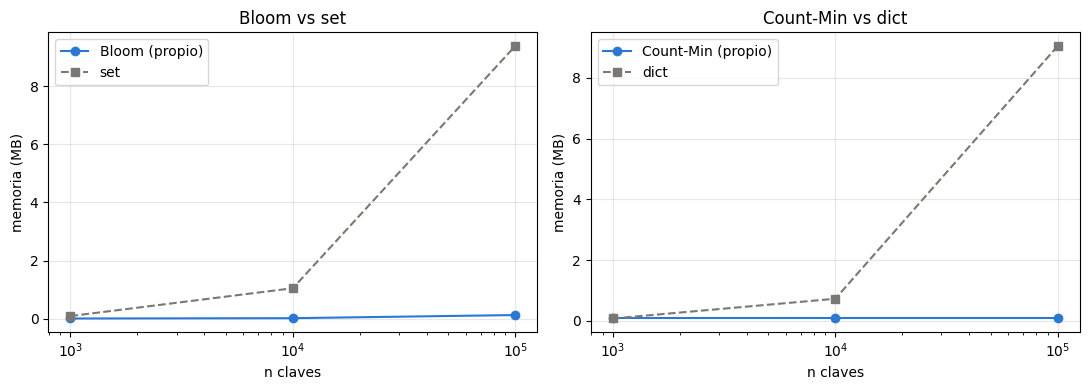

Memoria a 100K claves:
  Bloom 0.12 MB  vs  set 9.39 MB
  Count-Min 0.11 MB (fija)  vs  dict 9.04 MB


In [7]:
import sys

tamanos = [1_000, 10_000, 100_000]
bloom_mb, set_mb, cm_mb, dict_mb = [], [], [], []

for n in tamanos:
    claves = [f"ip:{i:08x}" for i in range(n)]
    b = FiltroBloom(n_esperado=n, prob_fp=0.01); b.actualizar(claves)
    bloom_mb.append(b.memoria_bytes / 1e6)
    s = set(claves)
    set_mb.append((sys.getsizeof(s) + sum(sys.getsizeof(k) for k in claves)) / 1e6)
    c = CountMinSketch(epsilon=0.001, delta=0.01)
    for k in claves: c.sumar(k)
    cm_mb.append(c.memoria_bytes / 1e6)
    d = {}
    for k in claves: d[k] = d.get(k, 0) + 1
    dict_mb.append((sys.getsizeof(d) + sum(sys.getsizeof(k) for k in d)) / 1e6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(tamanos, bloom_mb, "o-", label="Bloom (propio)", color="#2a78d6")
ax1.plot(tamanos, set_mb, "s--", label="set", color="#7a7873")
ax1.set_title("Bloom vs set"); ax1.set_xlabel("n claves"); ax1.set_ylabel("memoria (MB)")
ax1.set_xscale("log"); ax1.legend(); ax1.grid(True, alpha=.3)
ax2.plot(tamanos, cm_mb, "o-", label="Count-Min (propio)", color="#2a78d6")
ax2.plot(tamanos, dict_mb, "s--", label="dict", color="#7a7873")
ax2.set_title("Count-Min vs dict"); ax2.set_xlabel("n claves"); ax2.set_ylabel("memoria (MB)")
ax2.set_xscale("log"); ax2.legend(); ax2.grid(True, alpha=.3)
plt.tight_layout(); plt.show()

print("Memoria a 100K claves:")
print(f"  Bloom {bloom_mb[-1]:.2f} MB  vs  set {set_mb[-1]:.2f} MB")
print(f"  Count-Min {cm_mb[-1]:.2f} MB (fija)  vs  dict {dict_mb[-1]:.2f} MB")

## Conclusiones

- **Etapa 0:** la cola FIFO convierte en **O(1)** lo que una lista haría en O(n) por
  saque; el buffer circular es la alternativa de memoria fija.
- **Etapa 1:** *merge sort* estable garantiza **O(n log n)** en el peor caso y deja
  el lote ordenado y deduplicado (recall de deduplicación ≈ 99,7 %).
- **Etapa 6:** el **filtro de Bloom** (sin falsos negativos) y el **Count-Min
  Sketch** (nunca subestima) detectan fraude con **precisión ≈ 1,0 y recall ≈ 0,95**
  usando una fracción de la memoria de un `set`/`dict`.

La idea común: cambiar un poco de exactitud por **memoria acotada**, que es lo que
permite que el pipeline escale a millones de eventos.